# 03 · Exploratory Analysis — What Drives Conversion?
For every candidate driver we compute the **conversion rate** (share of contacts who subscribed) and compare it with the 11.3% baseline. A segment's **lift** = segment rate ÷ baseline rate.

In [15]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path("..")
FIG, TAB = ROOT / "outputs/figures", ROOT / "outputs/tables"
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)

NAVY, TEAL, ORANGE, GREY = "#1F3A5F", "#2A9D8F", "#E76F51", "#9AA5B1"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.labelsize": 10, "font.size": 10})
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 140)

In [16]:
df = pd.read_csv(ROOT / "data/bank_marketing_clean.csv")
BASE = df.subscribed.mean()
print(f"{len(df):,} customers | baseline conversion = {BASE:.2%}")

def conv_table(col, order=None, min_n=0):
    t = (df.groupby(col)["subscribed"].agg(customers="size", subscribers="sum", conversion_rate="mean"))
    t["lift"] = t.conversion_rate / BASE
    t = t[t.customers >= min_n]
    return t.loc[order] if order else t.sort_values("conversion_rate", ascending=False)

def bar_conv(col, order=None, title=None, fname=None, horizontal=True, figsize=(7, 4)):
    t = conv_table(col, order)
    fig, ax = plt.subplots(figsize=figsize)
    cols = [TEAL if r > BASE else GREY for r in t.conversion_rate]
    if horizontal:
        y = t.index[::-1].astype(str); v = t.conversion_rate[::-1] * 100
        ax.barh(y, v, color=cols[::-1]); ax.axvline(BASE * 100, color=ORANGE, ls="--", lw=1.4)
        for i, (val, n) in enumerate(zip(v, t.customers[::-1])): ax.text(val + .3, i, f"{val:.1f}%  (n={n:,})", va="center", fontsize=8.5)
        ax.set_xlabel("Conversion rate (%)"); ax.set_xlim(0, max(v) * 1.28)
    else:
        x = t.index.astype(str); v = t.conversion_rate * 100
        ax.bar(x, v, color=cols); ax.axhline(BASE * 100, color=ORANGE, ls="--", lw=1.4)
        for i, val in enumerate(v): ax.text(i, val + .4, f"{val:.1f}%", ha="center", fontsize=8.5)
        ax.set_ylabel("Conversion rate (%)")
    ax.set_title(title or f"Conversion rate by {col}")
    if fname: fig.savefig(FIG / fname)
    plt.show(); t.round(4).to_csv(TAB / f"03_conv_by_{col}.csv")
    return t

41,176 customers | baseline conversion = 11.27%


## 1. Who is the customer?

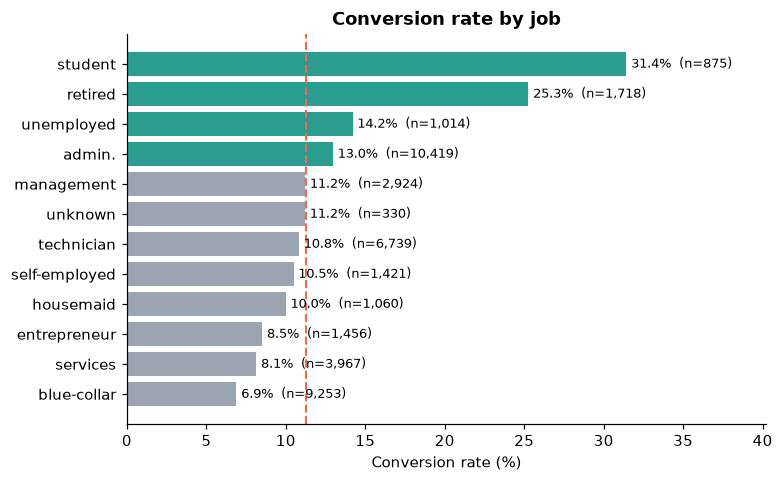

,customers,subscribers,conversion_rate,lift
job,,,,
student,875,275,0.314286,2.789616
retired,1718,434,0.252619,2.242262
unemployed,1014,144,0.142012,1.260504
admin.,10419,1351,0.129667,1.150930
management,2924,328,0.112175,0.995672
unknown,330,37,0.112121,0.995194
technician,6739,730,0.108325,0.961495
self-employed,1421,149,0.104856,0.930705
housemaid,1060,106,0.100000,0.887605


In [17]:
bar_conv("job", title="Conversion rate by job", fname="03_conv_by_job.png", figsize=(7.5, 4.6))

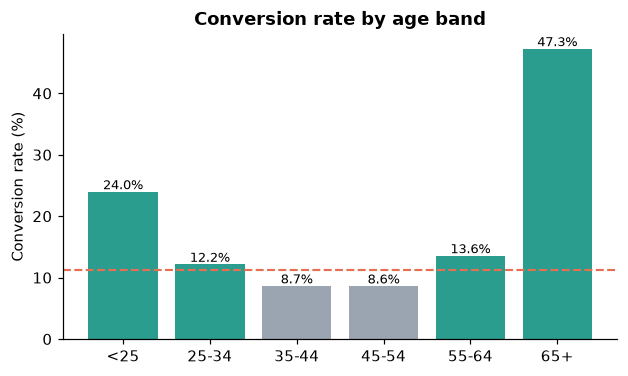

,customers,subscribers,conversion_rate,lift
age_band,,,,
<25,1067,256,0.239925,2.129587
25-34,13684,1666,0.121748,1.080642
35-44,13495,1168,0.086551,0.768227
45-54,8702,752,0.086417,0.767041
55-64,3566,484,0.135726,1.204714
65+,662,313,0.472810,4.196683


In [18]:
bar_conv("age_band", order=["<25", "25-34", "35-44", "45-54", "55-64", "65+"], title="Conversion rate by age band", fname="03_conv_by_age_band.png", horizontal=False, figsize=(6.5, 3.6))

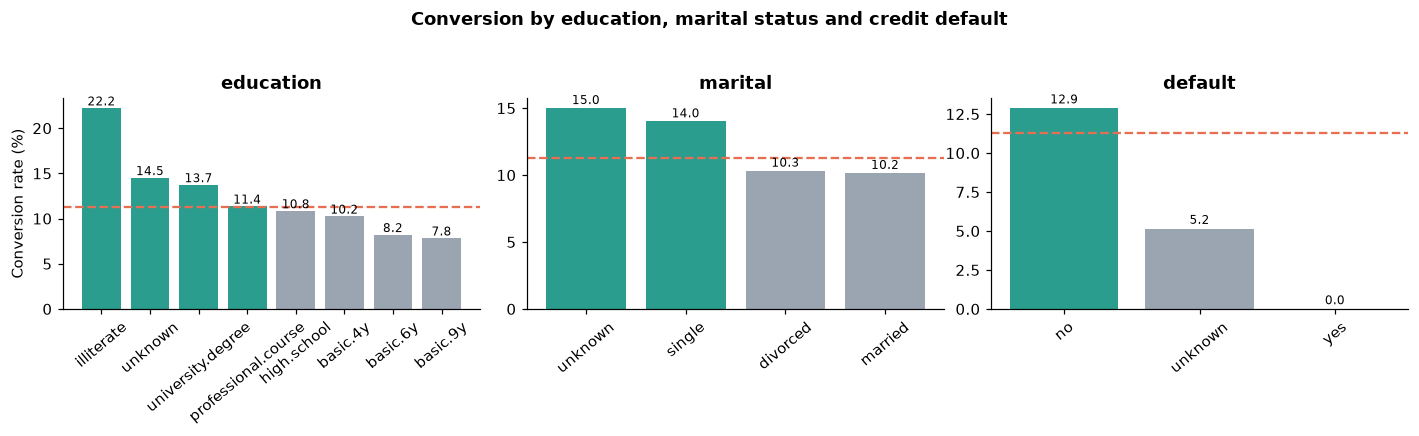

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, col in zip(axes, ["education", "marital", "default"]):
    t = conv_table(col); v = t.conversion_rate * 100
    ax.bar(t.index.astype(str), v, color=[TEAL if r > BASE else GREY for r in t.conversion_rate]); ax.axhline(BASE * 100, color=ORANGE, ls="--")
    ax.set_title(col); ax.tick_params(axis="x", rotation=40)
    for i, val in enumerate(v): ax.text(i, val + .3, f"{val:.1f}", ha="center", fontsize=8)
    t.round(4).to_csv(TAB / f"03_conv_by_{col}.csv")
axes[0].set_ylabel("Conversion rate (%)"); fig.suptitle("Conversion by education, marital status and credit default", fontweight="bold", y=1.03)
fig.tight_layout(); fig.savefig(FIG / "03_conv_by_demographics.png"); plt.show()

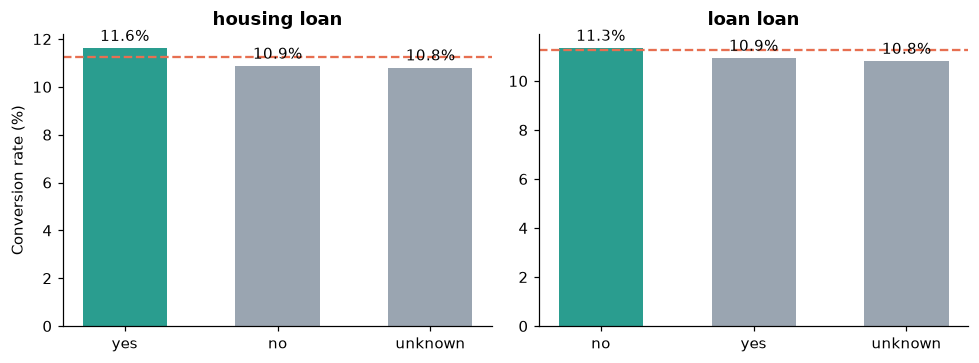

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for ax, col in zip(axes, ["housing", "loan"]):
    t = conv_table(col); v = t.conversion_rate * 100
    ax.bar(t.index.astype(str), v, color=[TEAL if r > BASE else GREY for r in t.conversion_rate], width=.55); ax.axhline(BASE * 100, color=ORANGE, ls="--")
    for i, val in enumerate(v): ax.text(i, val + .3, f"{val:.1f}%", ha="center")
    ax.set_title(f"{col} loan"); t.round(4).to_csv(TAB / f"03_conv_by_{col}.csv")
axes[0].set_ylabel("Conversion rate (%)"); fig.tight_layout(); fig.savefig(FIG / "03_conv_by_loans.png"); plt.show()

## 2. How was the customer contacted?

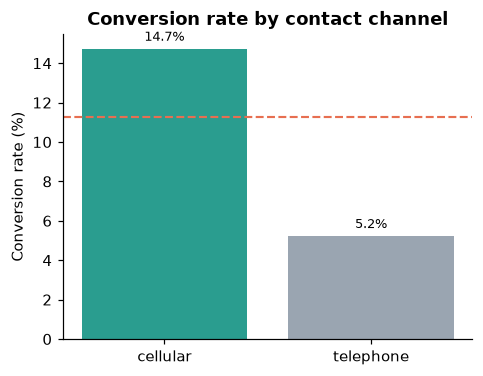

,customers,subscribers,conversion_rate,lift
contact,,,,
cellular,26135,3852,0.147389,1.308228
telephone,15041,787,0.052324,0.464427


In [21]:
bar_conv("contact", title="Conversion rate by contact channel", fname="03_conv_by_contact.png", horizontal=False, figsize=(4.8, 3.6))

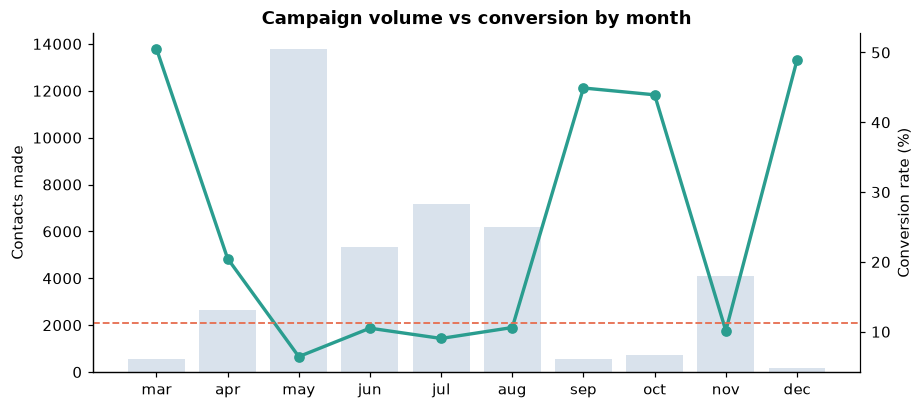

,customers,subscribers,conversion_rate,lift
month,,,,
mar,546,276,0.505,4.487
apr,2631,539,0.205,1.818
may,13767,886,0.064,0.571
jun,5318,559,0.105,0.933
jul,7169,648,0.090,0.802
aug,6176,655,0.106,0.941
sep,570,256,0.449,3.986
oct,717,315,0.439,3.900
nov,4100,416,0.101,0.901


In [22]:
months = ["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
t = conv_table("month", months)
fig, ax1 = plt.subplots(figsize=(9, 4))
ax1.bar(t.index, t.customers, color="#D9E2EC", label="Contacts made"); ax1.set_ylabel("Contacts made")
ax2 = ax1.twinx(); ax2.plot(t.index, t.conversion_rate * 100, color=TEAL, marker="o", lw=2.2, label="Conversion rate")
ax2.axhline(BASE * 100, color=ORANGE, ls="--", lw=1.2); ax2.set_ylabel("Conversion rate (%)"); ax2.spines["right"].set_visible(True)
ax1.set_title("Campaign volume vs conversion by month"); fig.savefig(FIG / "03_conv_by_month.png"); plt.show()
t.round(4).to_csv(TAB / "03_conv_by_month.csv"); t.round(3)

,customers,subscribers,conversion_rate,lift
day_of_week,,,,
mon,8512,847,0.100,0.883
tue,8086,953,0.118,1.046
wed,8134,949,0.117,1.036
thu,8618,1044,0.121,1.075
fri,7826,846,0.108,0.960


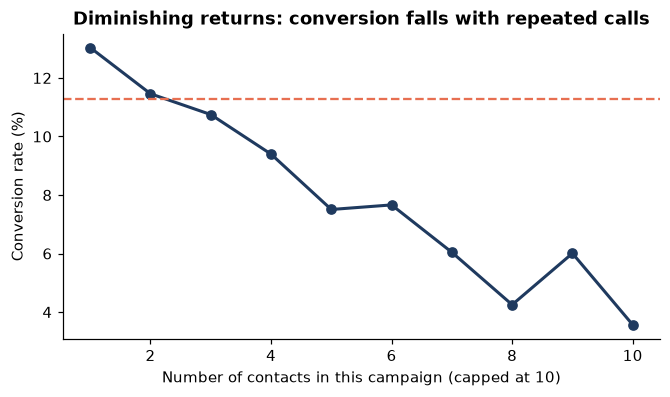

,campaign_capped,customers,conversion_rate
0,1,17634,0.130
1,2,10568,0.115
2,3,5340,0.107
3,4,2650,0.094
4,5,1599,0.075
5,6,979,0.077
6,7,629,0.060
7,8,400,0.042
8,9,283,0.060
9,10,1094,0.036


In [23]:
t = conv_table("day_of_week", ["mon", "tue", "wed", "thu", "fri"]); display(t.round(3)); t.round(4).to_csv(TAB / "03_conv_by_day_of_week.csv")
t2 = df.groupby("campaign_capped").subscribed.agg(customers="size", conversion_rate="mean").reset_index()
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(t2.campaign_capped, t2.conversion_rate * 100, marker="o", color=NAVY, lw=2); ax.axhline(BASE * 100, color=ORANGE, ls="--")
ax.set_xlabel("Number of contacts in this campaign (capped at 10)"); ax.set_ylabel("Conversion rate (%)")
ax.set_title("Diminishing returns: conversion falls with repeated calls"); fig.savefig(FIG / "03_conv_by_campaign_calls.png"); plt.show()
t2.round(4).to_csv(TAB / "03_conv_by_campaign_calls.csv"); t2.round(3)

## 3. Does history with the bank matter?

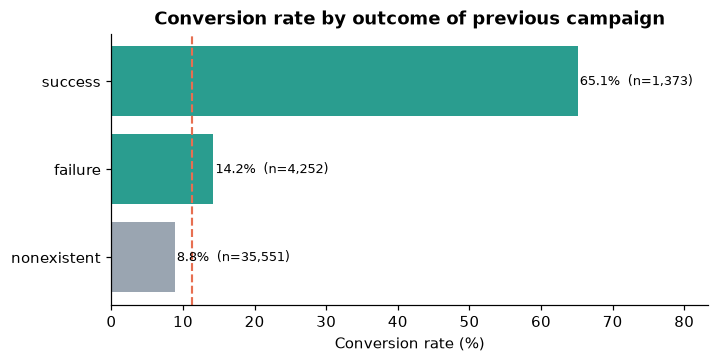

,customers,subscribers,conversion_rate,lift
poutcome,,,,
success,1373,894,0.651,5.779
failure,4252,605,0.142,1.263
nonexistent,35551,3140,0.088,0.784


In [24]:
t = bar_conv("poutcome", title="Conversion rate by outcome of previous campaign", fname="03_conv_by_poutcome.png", figsize=(7, 3.2)); t.round(3)

## 4. Macro-economic environment

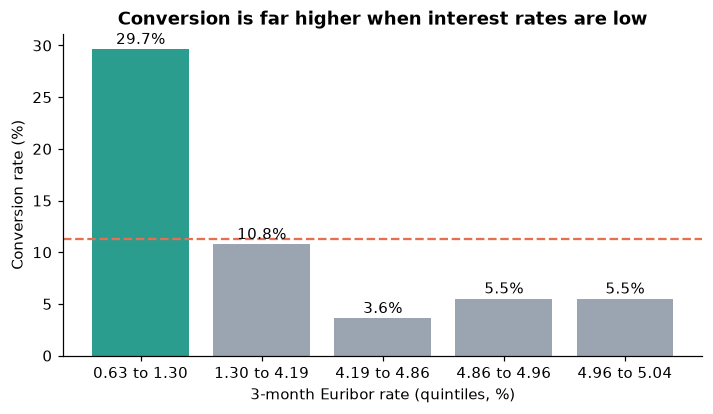

,customers,conversion_rate
0.63 to 1.30,8634,0.297
1.30 to 4.19,8427,0.108
4.19 to 4.86,8445,0.036
4.86 to 4.96,8496,0.055
4.96 to 5.04,7174,0.055


In [25]:
df["euribor_band"] = pd.qcut(df.euribor3m, 5, duplicates="drop").astype(str)
t = df.groupby(pd.qcut(df.euribor3m, 5, duplicates="drop"), observed=True).subscribed.agg(customers="size", conversion_rate="mean")
t.index = [f"{i.left:.2f} to {i.right:.2f}" for i in t.index]
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.bar(t.index, t.conversion_rate * 100, color=[TEAL if r > BASE else GREY for r in t.conversion_rate])
for i, v in enumerate(t.conversion_rate * 100): ax.text(i, v + .5, f"{v:.1f}%", ha="center")
ax.axhline(BASE * 100, color=ORANGE, ls="--"); ax.set_xlabel("3-month Euribor rate (quintiles, %)"); ax.set_ylabel("Conversion rate (%)")
ax.set_title("Conversion is far higher when interest rates are low"); fig.savefig(FIG / "03_conv_by_euribor.png"); plt.show()
t.round(4).to_csv(TAB / "03_conv_by_euribor.csv"); t.round(3)

## 5. Call duration — informative but unusable
Duration is the strongest single correlate of success, but it is only known **after** the call. A model using it would "predict" outcomes it effectively already knows, so we show it descriptively and exclude it from modelling in notebook 05.

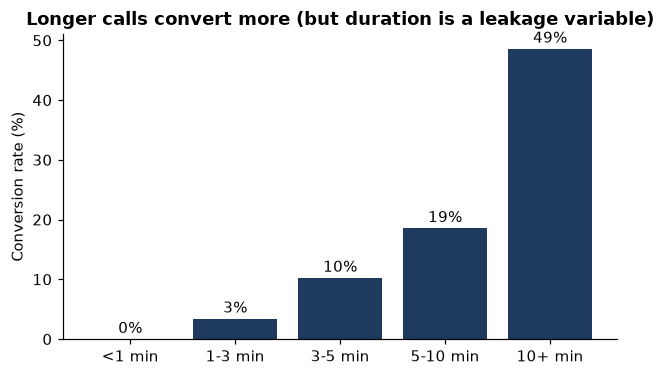

,customers,subscribers,conversion_rate,lift
duration_band,,,,
<1 min,4284,1,0.000,0.002
1-3 min,16412,563,0.034,0.304
3-5 min,9278,953,0.103,0.912
5-10 min,7738,1438,0.186,1.649
10+ min,3464,1684,0.486,4.315


In [26]:
t = conv_table("duration_band", ["<1 min", "1-3 min", "3-5 min", "5-10 min", "10+ min"])
fig, ax = plt.subplots(figsize=(6.5, 3.6)); ax.bar(t.index, t.conversion_rate * 100, color=NAVY)
for i, v in enumerate(t.conversion_rate * 100): ax.text(i, v + 1, f"{v:.0f}%", ha="center")
ax.set_ylabel("Conversion rate (%)"); ax.set_title("Longer calls convert more (but duration is a leakage variable)")
fig.savefig(FIG / "03_conv_by_duration.png"); plt.show(); t.round(4).to_csv(TAB / "03_conv_by_duration_band.csv"); t.round(3)

## 6. Correlation among numeric variables

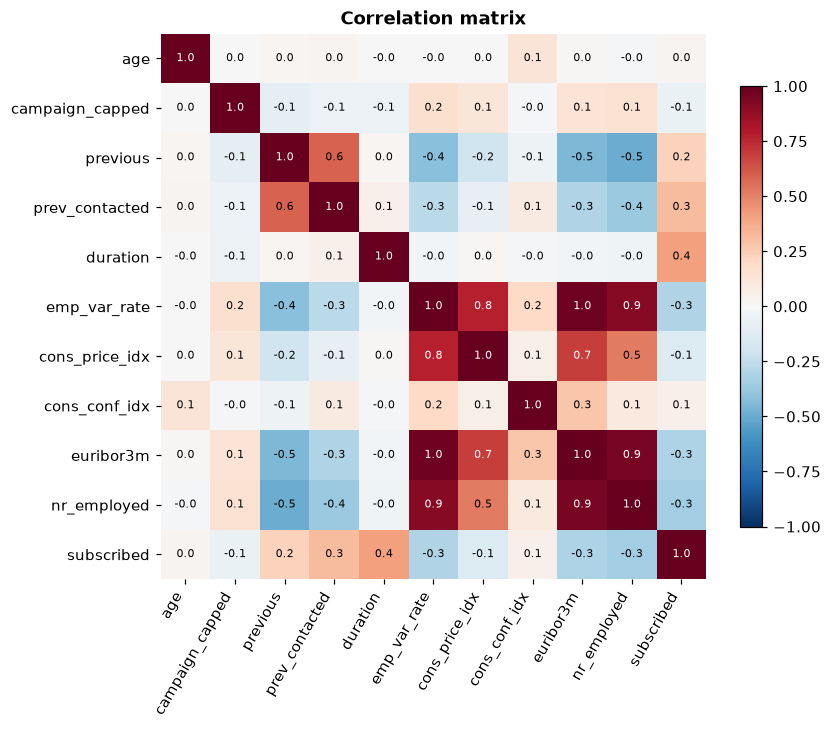

Correlation with subscription:


duration           0.41
nr_employed       -0.35
prev_contacted     0.32
euribor3m         -0.31
emp_var_rate      -0.30
previous           0.23
cons_price_idx    -0.14
campaign_capped   -0.07
cons_conf_idx      0.05
age                0.03
Name: subscribed, dtype: float64

In [27]:
num = ["age", "campaign_capped", "previous", "prev_contacted", "duration", "emp_var_rate", "cons_price_idx", "cons_conf_idx", "euribor3m", "nr_employed", "subscribed"]
corr = df[num].corr().round(2); corr.to_csv(TAB / "03_correlation_matrix.csv")
fig, ax = plt.subplots(figsize=(8, 6.5)); im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(num))); ax.set_xticklabels(num, rotation=60, ha="right"); ax.set_yticks(range(len(num))); ax.set_yticklabels(num)
for i in range(len(num)):
    for j in range(len(num)): ax.text(j, i, f"{corr.iloc[i, j]:.1f}", ha="center", va="center", fontsize=7, color="white" if abs(corr.iloc[i, j]) > .6 else "black")
fig.colorbar(im, shrink=.8); ax.set_title("Correlation matrix"); ax.spines[:].set_visible(False)
fig.savefig(FIG / "03_correlation_matrix.png"); plt.show()
print("Correlation with subscription:"); corr["subscribed"].drop("subscribed").sort_values(key=abs, ascending=False)

## 7. Summary ranking of drivers

In [28]:
rows = []
for col in ["job", "age_band", "education", "marital", "default", "housing", "loan", "contact", "month", "day_of_week", "poutcome", "campaign_capped", "prev_contacted"]:
    t = conv_table(col, min_n=100)
    rows.append({"driver": col, "best_segment": t.conversion_rate.idxmax(), "best_rate": t.conversion_rate.max(),
                 "worst_segment": t.conversion_rate.idxmin(), "worst_rate": t.conversion_rate.min(),
                 "spread_pp": (t.conversion_rate.max() - t.conversion_rate.min()) * 100})
drivers = pd.DataFrame(rows).sort_values("spread_pp", ascending=False).round(3)
drivers.to_csv(TAB / "03_driver_ranking.csv", index=False); drivers

,driver,best_segment,best_rate,worst_segment,worst_rate,spread_pp
10,poutcome,success,0.651,nonexistent,0.088,56.281
12,prev_contacted,1,0.638,0,0.093,54.570
8,month,mar,0.505,may,0.064,44.114
1,age_band,65+,0.473,45-54,0.086,38.639
0,job,student,0.314,blue-collar,0.069,24.534
7,contact,cellular,0.147,telephone,0.052,9.506
11,campaign_capped,1,0.130,10,0.036,9.472
4,default,no,0.129,unknown,0.052,7.727
2,education,unknown,0.145,basic.9y,0.078,6.684
3,marital,single,0.140,married,0.102,3.853


## Key findings
1. **Previous success is the strongest signal:** customers who said yes to an earlier campaign convert at **65.1%** vs 8.8% for never-contacted customers (**5.8x lift**), but they are only 1,373 people (3.3%).
2. **Age is U-shaped:** 65+ convert at **47.3%** and under-25s at **24.0%**, versus ~8.6% for ages 35-54. By job: **students 31.4%**, **retired 25.3%**, blue-collar only 6.9%.
3. **Channel matters:** cellular **14.7%** vs fixed telephone **5.2%** (2.8x).
4. **Timing / macro environment:** conversion is **29.6%** when the 3-month Euribor is in its lowest quintile, versus 3.6-5.5% in the three highest quintiles. May alone absorbed a third of all calls (13,767) at just 6.4%, while Mar/Sep/Oct/Dec converted at 44-51% on only ~2,000 calls combined (probably warmer, targeted lists).
5. **Diminishing returns:** conversion falls from **13.0%** on the first call to **3.6%** at 10+ calls.
6. Education, marital status, and housing/personal loans move conversion by less than ~4 pp (loans < 1 pp), so they are weak targeting levers.

> **Caution:** these are associations in observational data. Month and macro effects are entangled with *who* the bank chose to call and *when*; they should not be read as causal.